<a href="https://colab.research.google.com/github/HarjapP/4010Project/blob/main/stage2_lookback72_horizon6_(18-11-2026).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 <h1 style="text-align: center;">AIR-QUALITY FORECASTING</h1>

Here will be small intro paragraph of the project and what we're doing.

In [1]:
# IMPORTS:

import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import sklearn
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import time
import random
from copy import deepcopy
import copy
from itertools import product
import torch.nn.functional as F


<h2 style="text-align: center;">STAGE 1: Data, Baselines, MLP</h1>

In [2]:
# 1. Load data:

df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [3]:
# The CSV includes extra unnamed columns caused by trailing separators. We remove those columns because they contain no useful measurements.
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

In [4]:
# 2. Chronological order:

# Create a chronological datetime index by combine the Date and Time columns before splitting, and removed rows with invalid timestamps.
df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce",
)
df = df.dropna(subset=["DateTime"]).set_index("DateTime").sort_index()
df = df.drop(columns=["Date", "Time"])

print(f"Rows after removing invalid timestamps: {len(df)}")
print(f"Time span: {df.index.min()} to {df.index.max()}")
print(f"Chronological order: {df.index.is_monotonic_increasing}")

Rows after removing invalid timestamps: 9357
Time span: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Chronological order: True


In [5]:
# 3. Chronological splitting:

# Chronological 60/20/20 splitting because our goal is to predict future measurements from past observations.
# We also split before fitting imputation to prevent data leakage or scaling steps so their statistics can be calculated from training data only.
train_size = int(len(df) * 0.6)
val_size = int(len(df) * 0.2)

train_df = df.iloc[:train_size].copy()
val_df = df.iloc[train_size:train_size + val_size].copy()
test_df = df.iloc[train_size + val_size:].copy()

print(f"Train shape: {train_df.shape}")
print(f"Validation shape: {val_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Train ends: {train_df.index[-1]}")
print(f"Validation ends: {val_df.index[-1]}")
print(f"Test starts: {test_df.index[0]}")

print("Chronological split created: training precedes validation, which precedes test.")

Train shape: (5614, 13)
Validation shape: (1871, 13)
Test shape: (1872, 13)
Train ends: 2004-10-30 15:00:00
Validation ends: 2005-01-16 14:00:00
Test starts: 2005-01-16 15:00:00
Chronological split created: training precedes validation, which precedes test.


In [6]:
# 4. Handle missing values:

# -200 represents a missing measurement. We replace those values with NaN so they are not treated as real sensor readings.
train_missing = train_df.replace(-200, np.nan)
val_missing = val_df.replace(-200, np.nan)
test_missing = test_df.replace(-200, np.nan)

missing_summary = pd.DataFrame({
    "Train missing (%)": train_missing.isna().mean() * 100,
    "Validation missing (%)": val_missing.isna().mean() * 100,
    "Test missing (%)": test_missing.isna().mean() * 100,
}).round(2)
display(missing_summary.sort_values("Train missing (%)", ascending=False))

,Train missing (%),Validation missing (%),Test missing (%)
NMHC(GT),83.72,100.00,100.00
CO(GT),25.61,8.23,4.86
NO2(GT),24.62,10.80,3.10
NOx(GT),24.56,10.80,3.10
PT08.S1(CO),2.64,7.06,4.59
PT08.S2(NMHC),2.64,7.06,4.59
C6H6(GT),2.64,7.06,4.59
PT08.S3(NOx),2.64,7.06,4.59
PT08.S4(NO2),2.64,7.06,4.59
PT08.S5(O3),2.64,7.06,4.59


In [7]:
# 5. Drop NMHC(GT) feature:

# It's missing all of validation and test, so we drop it because it cannot be used for prediction.
columns_to_drop = ["NMHC(GT)"]
train_missing = train_missing.drop(columns=columns_to_drop)
val_missing = val_missing.drop(columns=columns_to_drop)
test_missing = test_missing.drop(columns=columns_to_drop)

In [8]:
# 6. Target and features selection:

# Benzene is the target variable.
TARGET_COL = "C6H6(GT)"
features = ["C6H6(GT)", "PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S5(O3)", "T", "RH", "AH"]
# Saving separate copies of the original benzene target values.
train_target_observed = train_missing[TARGET_COL].copy()
val_target_observed = val_missing[TARGET_COL].copy()

| Feature | Chemical / Parameter | Full Name |
|---|---|---|
| `C6H6(GT)` | C₆H₆ | Benzene (Ground Truth) |
| `PT08.S1(CO)` | CO | Carbon Monoxide |
| `PT08.S2(NMHC)` | NMHC | Non-Methane Hydrocarbons |
| `PT08.S5(O3)` | O₃ | Ozone |
| `T` | Temperature | Ambient Temperature (°C) |
| `RH` | Relative Humidity | Relative Humidity (%) |
| `AH` | Absolute Humidity | Absolute Humidity |

**Note:** The PT08 features represent sensor responses to specific
gases rather than their direct concentrations. These sensor readings
are used as input features to help predict the benzene concentration
(`C6H6(GT)`).

In [9]:
# 7. Handle missing values in features:

# We use forward-filling to replace missing values with the most recent available measurement.
# Forward-filling respects the chronological order of the data, and doesn't cause data leakage.
# The median of the training dataset is used as a fallback in the case where
# forward-filling cannot find a previous measurement (e.g., at the start of the dataset).

# Selecting the features from each set.
train_feature_raw = train_missing[features]
val_feature_raw = val_missing[features]
test_feature_raw = test_missing[features]
# Calculating the median using the training dataset only.
training_feature_medians = train_feature_raw.median()

# Defining the missing value imputation function.
def causal_impute_inputs(frame, fallback_values):
    return frame.ffill().fillna(fallback_values)

# Handle missing values in the features using forward-filling and median fallback.
train_processed = causal_impute_inputs(train_feature_raw, training_feature_medians)
val_processed = causal_impute_inputs(val_feature_raw, training_feature_medians)
test_processed = causal_impute_inputs(test_feature_raw, training_feature_medians)

print("Missing target observations retained for masking:", {
    "train": int(train_target_observed.isna().sum()),
    "validation": int(val_target_observed.isna().sum()),
})
print("Remaining missing input features:", {
    "train": int(train_processed.isna().sum().sum()),
    "validation": int(val_processed.isna().sum().sum()),
    "test": int(test_processed.isna().sum().sum()),
})

Missing target observations retained for masking: {'train': 148, 'validation': 132}
Remaining missing input features: {'train': 0, 'validation': 0, 'test': 0}


In [10]:
# 8. Scale inputs using training statistics; preserve observed target masks:

LOOKBACK = 72                               # Previous 72 hours as input
HORIZON = 6                                 # Predict the next HORIZON hours as output
STRIDE = 6                                  # Window step size: 6 hours => consecutive inputs overlap by 66 hours
target_idx = features.index(TARGET_COL)     # Finds position of Benzene within the features list

# Using StandardScaler to standardize the features.
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_processed[features])
val_scaled = scaler.transform(val_processed[features])
test_scaled = scaler.transform(test_processed[features])
# Extract target mean and scale for the target variable.
target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]

# Scale the target variable using the training statistics.
train_target_scaled = (train_target_observed.to_numpy() - target_mean) / target_scale
val_target_scaled = (val_target_observed.to_numpy() - target_mean) / target_scale


In [11]:
# 9. Create labeled windows for training and validation:

# Defining the function to create labeled windows.
# STRIDE < LOOKBACK guarantees consecutive windows overlap (stride 6 => they share LOOKBACK-6 hours of input).
assert STRIDE < LOOKBACK, "STRIDE must be smaller than LOOKBACK for overlapping windows"

def create_labeled_windows(input_data, target_data, lookback=LOOKBACK, horizon=HORIZON, stride=STRIDE):
    X, y, target_masks = [], [], []

    for start in range(0, len(input_data) - lookback - horizon + 1, stride):
        target_window = target_data[start + lookback : start + lookback + horizon]

        # Stores the previous LOOKBACK hours of input features.
        X.append(input_data[start : start + lookback])
        # Stores the benzene target values for the next HORIZON hours.
        y.append(target_window)
        # Identifies which target values are observed (not NaN) for masking during training.
        target_masks.append(np.isfinite(target_window))

    return np.asarray(X), np.asarray(y), np.asarray(target_masks)

# Each split is windowed independently; NaN targets remain masked, not imputed.
X_train, y_train, train_target_mask = create_labeled_windows(train_scaled, train_target_scaled)
X_val, y_val, val_target_mask = create_labeled_windows(val_scaled, val_target_scaled)

# Prepare test inputs only; do not create test labels or calculate test metrics in Stage 1.
X_test = np.asarray([
    test_scaled[start : start + LOOKBACK]
    for start in range(0, len(test_scaled) - LOOKBACK - HORIZON + 1, STRIDE)
])

print(f"Feature order: {features}")
print(f"Target: {TARGET_COL}; lookback: {LOOKBACK} hours; horizon: {HORIZON} hours")
print(f"Train: X={X_train.shape}, y={y_train.shape}; observed labels={int(train_target_mask.sum()):,}/{train_target_mask.size:,}")
print(f"Validation: X={X_val.shape}, y={y_val.shape}; observed labels={int(val_target_mask.sum()):,}/{val_target_mask.size:,}")
print(f"Test inputs prepared: X={X_test.shape}; test labels and metrics remain unused.")

# Overlap check: window t+1 should reuse the last (LOOKBACK - STRIDE) hours of window t's input.
overlap_hours = LOOKBACK - STRIDE
assert np.allclose(X_train[1][:overlap_hours], X_train[0][STRIDE:]), "Consecutive windows do not overlap as expected"
print(f"Windows overlap: consecutive windows share {overlap_hours} of {LOOKBACK} input hours (stride = {STRIDE} h).")

print("Training and validation windows created with masked missing target labels.")

Feature order: ['C6H6(GT)', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S5(O3)', 'T', 'RH', 'AH']
Target: C6H6(GT); lookback: 72 hours; horizon: 6 hours
Train: X=(5537, 72, 7), y=(5537, 6); observed labels=32,334/33,222
Validation: X=(1794, 72, 7), y=(1794, 6); observed labels=9,972/10,764
Test inputs prepared: X=(1795, 72, 7); test labels and metrics remain unused.
Windows overlap: consecutive windows share 71 of 72 input hours (stride = 1 h).
Training and validation windows created with masked missing target labels.


In [12]:
# 10. Dataset timestamp audit and exploratory figures.
time_deltas = df.index.to_series().diff().dropna()
native_interval = time_deltas.mode().iloc[0]
long_gaps = time_deltas[time_deltas > native_interval]

print(f"Rows: {len(df):,}")
print(f"Coverage: {df.index.min()} to {df.index.max()}")
print(f"Native sampling interval (mode): {native_interval}")
print(f"Duplicate timestamps: {int(df.index.duplicated().sum())}")
print(f"Intervals longer than the native interval: {len(long_gaps)}")
if not long_gaps.empty:
    print(f"Longest interval: {time_deltas.max()}")


Rows: 9,357
Coverage: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Native sampling interval (mode): 0 days 01:00:00
Duplicate timestamps: 0
Intervals longer than the native interval: 0


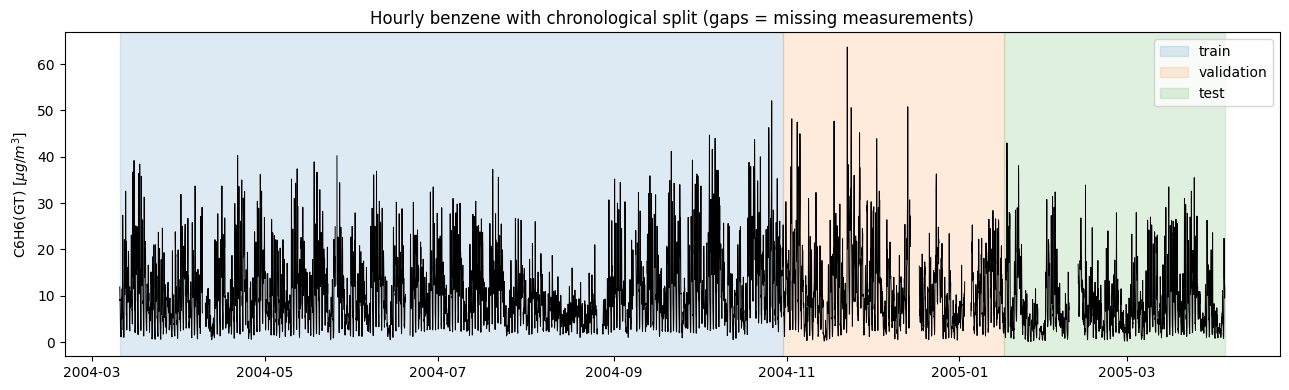

In [13]:
# Figure 1 — full target series with the chronological split drawn on it
target_series = df[TARGET_COL].replace(-200, np.nan)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(target_series.index, target_series, lw=0.7, color="k")
for part, c, lab in [
    (train_df, "tab:blue", "train"),
    (val_df, "tab:orange", "validation"),
    (test_df, "tab:green", "test"),
]:
    ax.axvspan(part.index.min(), part.index.max(), color=c, alpha=0.15, label=lab)
ax.set_ylabel(rf"{TARGET_COL} [$\mu g/m^3$]")
ax.set_title("Hourly benzene with chronological split (gaps = missing measurements)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

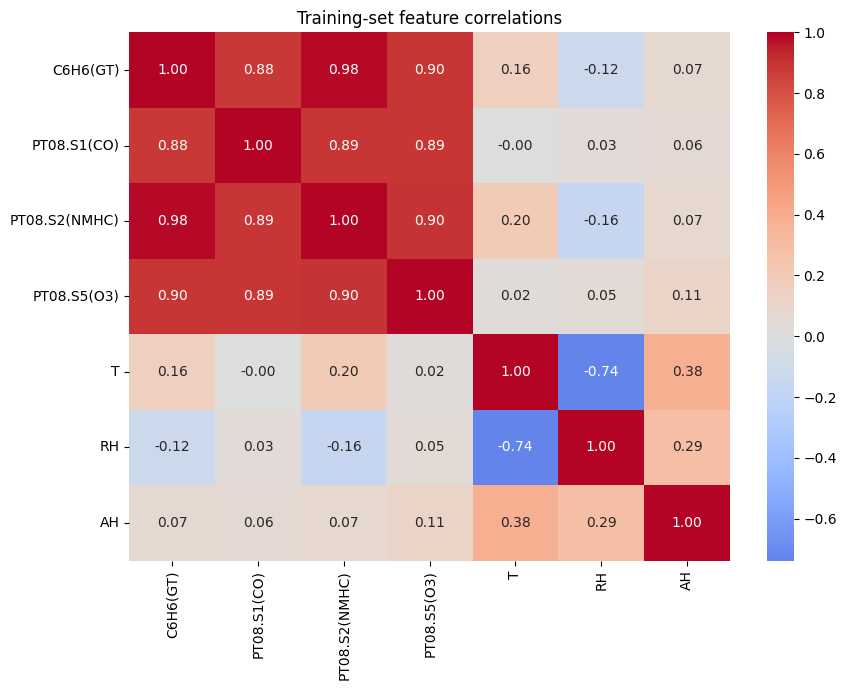

In [14]:
# Figure 2 — correlations calculated from training observations only
train_correlations = train_missing[features].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(train_correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Training-set feature correlations")
fig.tight_layout()
plt.show()

In [15]:
# 11. Seasonal-naive baseline — repeat the most recent HORIZON-hour target pattern:

# Using RMSE and MAE for evluation metrics.
# Accuracy and F1 are classification metrics, so not suitable in this case.

assert HORIZON <= LOOKBACK, "Baseline repeats the last HORIZON hours, so the lookback must cover at least HORIZON hours"
baseline_start = time.perf_counter()
baseline_pred_scaled = X_val[:, -HORIZON:, target_idx]
baseline_prediction_seconds = time.perf_counter() - baseline_start

# Undo target standardization so the reported errors are in the recorded units.
target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]
y_val_original = y_val * target_scale + target_mean
baseline_pred_original = baseline_pred_scaled * target_scale + target_mean

observed_val = val_target_mask
baseline_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], baseline_pred_original[observed_val]))
baseline_mae = mean_absolute_error(y_val_original[observed_val], baseline_pred_original[observed_val])

print("Baseline predictions and validation targets have shape:", baseline_pred_original.shape)
print(f"Metrics use only observed validation targets: {int(observed_val.sum()):,}/{observed_val.size:,} target values.")

Baseline predictions and validation targets have shape: (1794, 6)
Metrics use only observed validation targets: 9,972/10,764 target values.


In [16]:
# 12. MLP model — fully connected feedforward neural network:

# Setting random seeds for reproducibility.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters for the MLP model.
batch_size = 64
epochs = 15
learning_rate = 0.001

# Prepare the training data loader with masked targets for the MLP model.
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
        torch.tensor(train_target_mask, dtype=torch.float32),
    ),
    batch_size=batch_size,
    shuffle=True,
)

# Define the MLP model architecture.
class TimeSeriesMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        return self.network(x)

mlp_model = TimeSeriesMLP(LOOKBACK, len(features), HORIZON).to(device)
mlp_parameter_count = sum(parameter.numel() for parameter in mlp_model.parameters() if parameter.requires_grad)

### MLP Architecture

| Layer | Operation | Output Size | Activation |
|---|---|---|---|
| Input | 72-hour input with 7 features | (72, 7) | — |
| Flatten | Converts input into a 1D vector | 504 | — |
| Fully Connected 1 | Dense layer with 128 neurons | 128 | ReLU |
| Dropout | Dropout rate of 0.2 | 128 | — |
| Fully Connected 2 | Dense layer with 64 neurons | 64 | ReLU |
| Output Layer | Dense layer with 6 neurons | 6 | — |

**Input:** 72 hours of air quality data with 7 features (504 total input values).

**Output:** 6 predicted benzene concentrations, representing the next 6 hours.

ReLU helps the MLP learn complex nonlinear patterns, while Dropout (0.2) helps prevent the model from overfitting those patterns to the training data.

Trained on 5537 training windows; evaluated on 1794 validation windows.


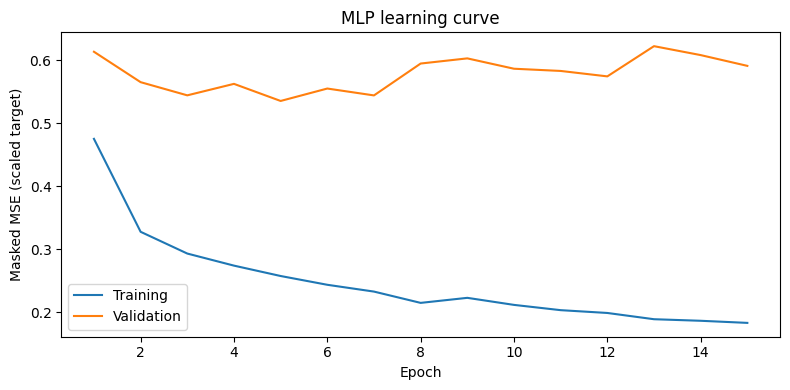

In [17]:
# Define a masked mean squared error loss function that ignores missing target values during training.
def masked_mse_loss(predictions, targets, target_mask):
    squared_errors = (predictions - targets).square() * target_mask
    return squared_errors.sum() / target_mask.sum().clamp_min(1.0)


criterion = masked_mse_loss
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=learning_rate)
mlp_training_losses, mlp_validation_losses = [], []
val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
val_targets_tensor = torch.tensor(np.nan_to_num(y_val, nan=0.0), dtype=torch.float32, device=device)
val_mask_tensor = torch.tensor(val_target_mask, dtype=torch.float32, device=device)

# Only training batches contribute gradients or optimizer updates.
mlp_training_start = time.perf_counter()
for epoch in range(epochs):
    mlp_model.train()
    epoch_loss_sum, epoch_target_count = 0.0, 0
    for batch_x, batch_y, batch_mask in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        batch_mask = batch_mask.to(device)

        optimizer.zero_grad()
        predictions = mlp_model(batch_x)
        loss = criterion(predictions, batch_y, batch_mask)
        loss.backward()
        optimizer.step()
        observed_count = int(batch_mask.sum().item())
        epoch_loss_sum += loss.item() * observed_count
        epoch_target_count += observed_count

    mlp_training_losses.append(epoch_loss_sum / epoch_target_count)
    mlp_model.eval()
    with torch.no_grad():
        val_predictions = mlp_model(val_tensor)
        mlp_validation_losses.append(
            criterion(val_predictions, val_targets_tensor, val_mask_tensor).item()
        )
mlp_training_seconds = time.perf_counter() - mlp_training_start

# Validation is evaluation-only; it does not update model parameters.
mlp_model.eval()
validation_start = time.perf_counter()
with torch.no_grad():
    mlp_pred_scaled = mlp_model(val_tensor).cpu().numpy()
mlp_prediction_seconds = time.perf_counter() - validation_start

mlp_pred_original = mlp_pred_scaled * target_scale + target_mean
mlp_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], mlp_pred_original[observed_val]))
mlp_mae = mean_absolute_error(y_val_original[observed_val], mlp_pred_original[observed_val])

print(f"Trained on {len(X_train)} training windows; evaluated on {len(X_val)} validation windows.")

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), mlp_training_losses, label="Training")
plt.plot(range(1, epochs + 1), mlp_validation_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE (scaled target)")
plt.title("MLP learning curve")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# 13. 1D CNN model — convolutional neural network for time series:

# Reset the seed so this model's initialization and batch order are reproducible.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Define the 1D CNN model architecture.
class TimeSeriesCNN(nn.Module):
    def __init__(self, num_features, horizon):
        super().__init__()
        self.conv1 = nn.Conv1d(
            in_channels=num_features,
            out_channels=64,
            kernel_size=3,
            padding=1,
        )
        self.relu = nn.ReLU()
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.head = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, horizon),
        )

    def forward(self, x):
        # Input is [batch, lookback, features]; Conv1d expects channels second.
        x = x.permute(0, 2, 1)
        x = self.relu(self.conv1(x))
        x = self.pool(x).squeeze(-1)
        return self.head(x)

cnn_model = TimeSeriesCNN(len(features), HORIZON).to(device)
cnn_parameter_count = sum(parameter.numel() for parameter in cnn_model.parameters() if parameter.requires_grad)
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=learning_rate)
cnn_training_losses, cnn_validation_losses = [], []



### 1D CNN Architecture

| Layer | Operation | Output Size | Activation |
|---|---|---|---|
| Input | 72-hour sequence with 7 features | (7, 72) | — |
| Conv1D | 64 filters, kernel size 3, padding 1 | (64, 72) | ReLU |
| Adaptive Max Pooling | Pooling to output size 1 | (64, 1) | — |
| Flatten / Squeeze | Remove final singleton dimension | 64 | — |
| Fully Connected 1 | Dense layer with 64 neurons | 64 | ReLU |
| Output Layer | Dense layer with 6 neurons | 6 | — |

**Input:** 72 hours of air quality data with 7 features.

**Output:** 6 predicted benzene concentrations, representing the next 6 hours.

**Why CNN?** The 1D CNN uses convolutional filters to detect local temporal patterns in the air quality data, while adaptive max pooling summarizes the strongest detected features before generating the forecasts.


Trained on 5537 training windows; evaluated on 1794 validation windows.


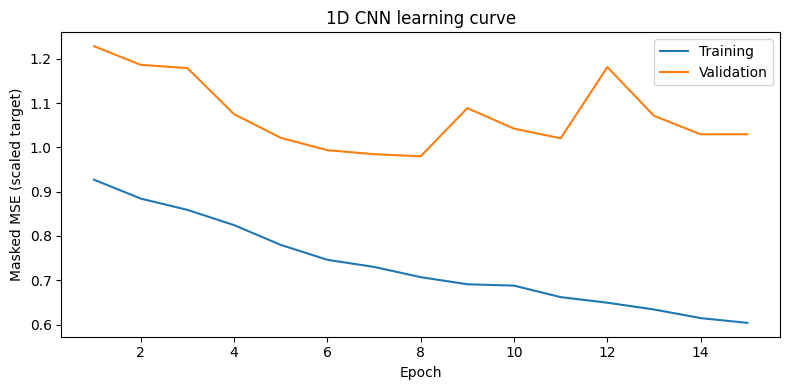

In [19]:
# Use the same training windows, loss, optimizer, epochs, and batch size as the MLP.
cnn_training_start = time.perf_counter()
for epoch in range(epochs):
    cnn_model.train()
    epoch_loss_sum, epoch_target_count = 0.0, 0
    for batch_x, batch_y, batch_mask in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        batch_mask = batch_mask.to(device)

        cnn_optimizer.zero_grad()
        predictions = cnn_model(batch_x)
        loss = criterion(predictions, batch_y, batch_mask)
        loss.backward()
        cnn_optimizer.step()
        observed_count = int(batch_mask.sum().item())
        epoch_loss_sum += loss.item() * observed_count
        epoch_target_count += observed_count

    cnn_training_losses.append(epoch_loss_sum / epoch_target_count)
    cnn_model.eval()
    with torch.no_grad():
        val_predictions = cnn_model(val_tensor)
        cnn_validation_losses.append(
            criterion(val_predictions, val_targets_tensor, val_mask_tensor).item()
        )
cnn_training_seconds = time.perf_counter() - cnn_training_start

# Validation is evaluation-only and does not update CNN parameters.
cnn_model.eval()
cnn_validation_start = time.perf_counter()
with torch.no_grad():
    cnn_pred_scaled = cnn_model(val_tensor).cpu().numpy()
cnn_prediction_seconds = time.perf_counter() - cnn_validation_start

cnn_pred_original = cnn_pred_scaled * target_scale + target_mean
cnn_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], cnn_pred_original[observed_val]))
cnn_mae = mean_absolute_error(y_val_original[observed_val], cnn_pred_original[observed_val])

print(f"Trained on {len(X_train)} training windows; evaluated on {len(X_val)} validation windows.")


plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), cnn_training_losses, label="Training")
plt.plot(range(1, epochs + 1), cnn_validation_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE (scaled target)")
plt.title("1D CNN learning curve")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# 14. Compare the seasonal-naive baseline, MLP, and 1D CNN models:

cnn_stage_comparison = pd.DataFrame([
    {
        "Model": "Seasonal naive",
        "Validation RMSE": baseline_rmse,
        "Validation MAE": baseline_mae,
        "Trainable parameters": 0,
        "Training time (seconds)": 0.0,
        "Validation prediction time (seconds)": baseline_prediction_seconds,
    },
    {
        "Model": "MLP",
        "Validation RMSE": mlp_rmse,
        "Validation MAE": mlp_mae,
        "Trainable parameters": mlp_parameter_count,
        "Training time (seconds)": mlp_training_seconds,
        "Validation prediction time (seconds)": mlp_prediction_seconds,
    },
    {
        "Model": "1D CNN",
        "Validation RMSE": cnn_rmse,
        "Validation MAE": cnn_mae,
        "Trainable parameters": cnn_parameter_count,
        "Training time (seconds)": cnn_training_seconds,
        "Validation prediction time (seconds)": cnn_prediction_seconds,
    },
]).sort_values("Validation RMSE").reset_index(drop=True)

cnn_stage_comparison["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - cnn_stage_comparison["Validation RMSE"]) / baseline_rmse * 100
)
cnn_stage_comparison.loc[cnn_stage_comparison["Model"] == "Seasonal naive", "RMSE improvement over baseline (%)"] = 0.0

display(cnn_stage_comparison.round(4))
print(f"Lowest validation RMSE among these models: {cnn_stage_comparison.iloc[0]['Model']}.")


,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,MLP,5.6066,3.7328,73286,4.5206,0.0050,45.9948
1,1D CNN,7.3974,5.4990,5958,9.0752,0.0967,28.7448
2,Seasonal naive,10.3816,7.7813,0,0.0000,0.0012,0.0000


Lowest validation RMSE among these models: MLP.


In [21]:
# 15. Grid Search on MLP hyperparameters:

# Tuning the lr, hidden-layer size, and dropout.
learning_rates = [0.001, 0.005, 0.01]
hidden_layer_options = [(128, 64), (256, 128)]
grid_epochs = epochs
grid_batch_size = batch_size
dropout_options = [0.1, 0.2]
grid_results = []
best_mlp_val_rmse = float("inf")
best_mlp_config = None
best_mlp_state = None

# Define a flexible MLP model.
class GridSearchMLP(nn.Module):
    def __init__(self, lookback, num_features, horizon, hidden_sizes, dropout):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * num_features, hidden_sizes[0]),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_sizes[0], hidden_sizes[1]),
            nn.ReLU(),
            nn.Linear(hidden_sizes[1], horizon),
        )

    def forward(self, x):
        return self.network(x)

# Grid search over the combinations of learning rates, hidden layer sizes, and dropout rates.
for trial, (lr, hidden_sizes, dropout) in enumerate(
    [(lr, widths, dropout) for lr in learning_rates
     for dropout in dropout_options for widths in hidden_layer_options],
    start=1,
):
    trial_seed = SEED + trial
    random.seed(trial_seed)
    np.random.seed(trial_seed)
    torch.manual_seed(trial_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(trial_seed)

    loader_generator = torch.Generator().manual_seed(trial_seed)
    trial_train_loader = DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
            torch.tensor(train_target_mask, dtype=torch.float32),
        ),
        batch_size=grid_batch_size,
        shuffle=True,
        generator=loader_generator,
    )
    trial_model = GridSearchMLP(LOOKBACK, len(features), HORIZON, hidden_sizes, dropout).to(device)
    trial_parameters = sum(p.numel() for p in trial_model.parameters() if p.requires_grad)
    trial_optimizer = torch.optim.Adam(trial_model.parameters(), lr=lr)

    trial_start = time.perf_counter()
    for epoch in range(grid_epochs):
        trial_model.train()
        for batch_x, batch_y, batch_mask in trial_train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)
            batch_mask = batch_mask.to(device)
            trial_optimizer.zero_grad()
            trial_loss = criterion(trial_model(batch_x), batch_y, batch_mask)
            trial_loss.backward()
            trial_optimizer.step()
    trial_training_seconds = time.perf_counter() - trial_start

    trial_model.eval()
    with torch.no_grad():
        trial_prediction_scaled = trial_model(val_tensor).cpu().numpy()
    trial_prediction_original = trial_prediction_scaled * target_scale + target_mean
    trial_rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], trial_prediction_original[observed_val]))
    trial_mae = mean_absolute_error(y_val_original[observed_val], trial_prediction_original[observed_val])

    config = {
        "learning_rate": lr,
        "hidden_sizes": hidden_sizes,
        "dropout": dropout,
        "batch_size": grid_batch_size,
        "epochs": grid_epochs,
    }
    grid_results.append({
        "Trial": trial,
        "Learning rate": lr,
        "Hidden layers": str(hidden_sizes),
        "Dropout": dropout,
        "Batch size": grid_batch_size,
        "Epochs": grid_epochs,
        "Validation RMSE": trial_rmse,
        "Validation MAE": trial_mae,
        "Trainable parameters": trial_parameters,
        "Training time (seconds)": trial_training_seconds,
    })

    if trial_rmse < best_mlp_val_rmse:
        best_mlp_val_rmse = trial_rmse
        best_mlp_config = config
        best_mlp_state = deepcopy(trial_model.state_dict())

# Grid search results.
mlp_grid_results = pd.DataFrame(grid_results)
display(mlp_grid_results.round(4).set_index("Trial"))
print("Selected MLP configuration (validation RMSE):", best_mlp_config)
print(f"Best validation RMSE: {best_mlp_val_rmse:.4f}")
print("Grid search complete; selected configuration:", best_mlp_config)

,Learning rate,Hidden layers,Dropout,Batch size,Epochs,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds)
Trial,,,,,,,,,
1,0.001,"(128, 64)",0.1,64,15,5.7925,3.8450,73286,4.0440
2,0.001,"(256, 128)",0.1,64,15,5.7118,3.8813,162950,4.9537
3,0.001,"(128, 64)",0.2,64,15,5.6257,3.7672,73286,3.8112
4,0.001,"(256, 128)",0.2,64,15,5.7550,3.8721,162950,5.5745
5,0.005,"(128, 64)",0.1,64,15,6.2033,4.1627,73286,3.3053
6,0.005,"(256, 128)",0.1,64,15,6.1945,4.2769,162950,5.5005
7,0.005,"(128, 64)",0.2,64,15,5.8075,3.9291,73286,3.8538
8,0.005,"(256, 128)",0.2,64,15,5.8673,4.0079,162950,4.8445
9,0.010,"(128, 64)",0.1,64,15,5.8309,3.9865,73286,3.6245


Selected MLP configuration (validation RMSE): {'learning_rate': 0.001, 'hidden_sizes': (128, 64), 'dropout': 0.2, 'batch_size': 64, 'epochs': 15}
Best validation RMSE: 5.6257
Grid search complete; selected configuration: {'learning_rate': 0.001, 'hidden_sizes': (128, 64), 'dropout': 0.2, 'batch_size': 64, 'epochs': 15}


In [22]:
# 16. Compare all Stage 1 models:

selected_trial = mlp_grid_results.iloc[0]
selected_config = best_mlp_config
selected_mlp = GridSearchMLP(
    LOOKBACK,
    len(features),
    HORIZON,
    selected_config["hidden_sizes"],
    selected_config["dropout"],
).to(device)
selected_mlp.load_state_dict(best_mlp_state)
selected_mlp.eval()

if device.type == "cuda":
    torch.cuda.synchronize(device)
selected_prediction_start = time.perf_counter()
with torch.no_grad():
    selected_prediction_scaled = selected_mlp(val_tensor).cpu().numpy()
if device.type == "cuda":
    torch.cuda.synchronize(device)
selected_prediction_seconds = time.perf_counter() - selected_prediction_start
selected_prediction_original = selected_prediction_scaled * target_scale + target_mean
selected_validation_rmse = np.sqrt(
    mean_squared_error(y_val_original[observed_val], selected_prediction_original[observed_val])
)
selected_validation_mae = mean_absolute_error(
    y_val_original[observed_val], selected_prediction_original[observed_val]
)
selected_parameters = sum(
    parameter.numel() for parameter in selected_mlp.parameters() if parameter.requires_grad
)

final_validation_comparison = pd.DataFrame([
    {
        "Model": "Seasonal naive",
        "Validation RMSE": baseline_rmse,
        "Validation MAE": baseline_mae,
        "Trainable parameters": 0,
        "Training time (seconds)": 0.0,
        "Validation prediction time (seconds)": baseline_prediction_seconds,
    },
    {
        "Model": "MLP (untuned)",
        "Validation RMSE": mlp_rmse,
        "Validation MAE": mlp_mae,
        "Trainable parameters": mlp_parameter_count,
        "Training time (seconds)": mlp_training_seconds,
        "Validation prediction time (seconds)": mlp_prediction_seconds,
    },
    {
        "Model": "1D CNN",
        "Validation RMSE": cnn_rmse,
        "Validation MAE": cnn_mae,
        "Trainable parameters": cnn_parameter_count,
        "Training time (seconds)": cnn_training_seconds,
        "Validation prediction time (seconds)": cnn_prediction_seconds,
    },
    {
        "Model": "MLP (grid-search selected)",
        "Validation RMSE": selected_validation_rmse,
        "Validation MAE": selected_validation_mae,
        "Trainable parameters": selected_parameters,
        "Training time (seconds)": selected_trial["Training time (seconds)"],
        "Validation prediction time (seconds)": selected_prediction_seconds,
    },
])
final_validation_comparison["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - final_validation_comparison["Validation RMSE"]) / baseline_rmse * 100
)
final_validation_comparison = final_validation_comparison.sort_values(
    "Validation RMSE"
).reset_index(drop=True)
display(final_validation_comparison.round(4))
print("Lowest validation RMSE:", final_validation_comparison.iloc[0]["Model"])


,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,MLP (untuned),5.6066,3.7328,73286,4.5206,0.0050,45.9948
1,MLP (grid-search selected),5.6257,3.7672,73286,4.0440,0.0078,45.8105
2,1D CNN,7.3974,5.4990,5958,9.0752,0.0967,28.7448
3,Seasonal naive,10.3816,7.7813,0,0.0000,0.0012,0.0000


Lowest validation RMSE: MLP (untuned)


<h2 style="text-align: center;">STAGE 2: Sequence models (Recurrent family), CNN, TCN, Grid-Search
Hyperparameter Optimization (HPO)</h1>

In [23]:
# 17. STAGE 2 setup — HPO design is declared BEFORE any Stage 2 result is produced:


# Shared settings: identical for every new model (controlled comparison).
# Same split, windows, masked-MSE loss, optimizer (Adam) and metrics as Stage 1.
MAX_EPOCHS = 15
BATCH_SIZE = 64
PATIENCE = 4          # early stopping on validation masked MSE (once a certain value is reached and value doesnt improve, activate early stopping)
GRAD_CLIP = 1.0       # gradient-norm clipping (helps the recurrent models)
DEFAULT_CFG = {"lr": 0.001, "hidden_size": 64, "dropout": 0.1} #clipping the gradients to a certain weight (<1) to combat gradient exploding (number keeps compounding and learning diverges)

# HPO design: tune ONE model (the best new model from the untuned comparison).
HPO_SPACE = {
    "lr": [0.001, 0.005, 0.01], #Different combinations of hyperparameters will be tested

    "hidden_size": [32, 64],      # hidden units (RNN/LSTM/GRU) or channels (TCN)
                                  #hidden size = number of units in the hidden representation of model, increases model's capacity to learn
    "dropout": [0.1, 0.3],        #Randomly cuts off 10% of neurons during training to reduce risk of overfitting
}
HPO_TRIALS = list(product(*HPO_SPACE.values()))
HPO_BUDGET = 12 #number of times we will be running optimzation (testing all combinations)
assert len(HPO_TRIALS) == HPO_BUDGET

print("STAGE 2 DESIGN (fixed before results)")
print(f"  Search space : {HPO_SPACE}")
print(f"  Budget       : {HPO_BUDGET} trials (full grid), max {MAX_EPOCHS} epochs each, batch size {BATCH_SIZE}")
print("  Objective    : minimise validation RMSE (original units, observed targets only)")
print(f"  Stopping rule: early stop when validation masked MSE does not improve for {PATIENCE} epochs;")
print("                 the best-epoch weights are restored. No extra trials after the grid finishes.")
print("  Which model  : best untuned new model (RNN/LSTM/GRU/TCN) by validation RMSE")
print("  Final choice : lowest validation RMSE among all trained models; if within 0.5% of the best,")
print("                 the model with fewer parameters wins. Test data is never used.")

STAGE 2 DESIGN (fixed before results)
  Search space : {'lr': [0.001, 0.005, 0.01], 'hidden_size': [32, 64], 'dropout': [0.1, 0.3]}
  Budget       : 12 trials (full grid), max 15 epochs each, batch size 64
  Objective    : minimise validation RMSE (original units, observed targets only)
  Stopping rule: early stop when validation masked MSE does not improve for 4 epochs;
                 the best-epoch weights are restored. No extra trials after the grid finishes.
  Which model  : best untuned new model (RNN/LSTM/GRU/TCN) by validation RMSE
  Final choice : lowest validation RMSE among all trained models; if within 0.5% of the best,
                 the model with fewer parameters wins. Test data is never used.


In [24]:
# 18. Sequence model definitions:

# RNN / LSTM / GRU share one wrapper: last hidden output -> small dropout + MLP head -> HORIZON outputs.
class RecurrentForecaster(nn.Module):
    def __init__(self, cell, num_features, horizon, hidden_size=64, dropout=0.1):
        super().__init__()
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = rnn_cls(num_features, hidden_size, num_layers=1, batch_first=True)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, horizon),
        )

    def forward(self, x):                      # x: [batch, lookback, features]
        out, _ = self.rnn(x)
        return self.head(out[:, -1, :])        # last time step summarises the 72-hour window
#RNN: USES

# TCN: causal, dilated convolutions with residual blocks (no future leakage inside the window).
class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.pad, 0)))   # left-pad only => causal


class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel_size, dilation)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout)
        self.skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = self.drop(self.relu(self.conv1(x)))
        out = self.drop(self.relu(self.conv2(out)))
        return self.relu(out + self.skip(x))


class TCNForecaster(nn.Module):
    # Dilations (1,2,4,8,16), kernel 3, two convs per block -> receptive field = 1 + 2*2*31 = 125 >= 72 hours.
    def __init__(self, num_features, horizon, channels=64, dropout=0.1,
                 kernel_size=3, dilations=(1, 2, 4, 8, 16)):
        super().__init__()
        blocks, in_ch = [], num_features
        for d in dilations:
            blocks.append(TCNBlock(in_ch, channels, kernel_size, d, dropout))
            in_ch = channels
        self.tcn = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Linear(channels, channels), nn.ReLU(), nn.Linear(channels, horizon))

    def forward(self, x):
        h = self.tcn(x.permute(0, 2, 1))[:, :, -1]   # features at the most recent hour
        return self.head(h)

In [25]:
# 19. Shared training / evaluation helpers — used by EVERY new model and every HPO trial:

METRIC_COLS = ["Validation RMSE", "Validation MAE", "Trainable parameters",
               "Training time (seconds)", "Validation prediction time (seconds)"]

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize(device)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Architecture "spec" = a small, serialisable description used to rebuild a model (also for the checkpoint).
def arch_spec(name, hidden_size, dropout):
    if name in ("RNN", "LSTM", "GRU"):
        return {"class": "RecurrentForecaster", "kwargs": {"cell": name, "hidden_size": hidden_size, "dropout": dropout}}
    if name == "TCN":
        return {"class": "TCNForecaster", "kwargs": {"hidden_size": hidden_size, "dropout": dropout}}
    raise ValueError(name)

def build_from_spec(spec):
    kw, c = spec["kwargs"], spec["class"]
    if c == "TimeSeriesMLP":
        return TimeSeriesMLP(LOOKBACK, len(features), HORIZON)
    if c == "TimeSeriesCNN":
        return TimeSeriesCNN(len(features), HORIZON)
    if c == "GridSearchMLP":
        return GridSearchMLP(LOOKBACK, len(features), HORIZON, tuple(kw["hidden_sizes"]), kw["dropout"])
    if c == "RecurrentForecaster":
        return RecurrentForecaster(kw["cell"], len(features), HORIZON, kw["hidden_size"], kw["dropout"])
    if c == "TCNForecaster":
        return TCNForecaster(len(features), HORIZON, kw["hidden_size"], kw["dropout"])
    raise ValueError(c)

def make_train_loader(seed, batch_size):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(
        TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(np.nan_to_num(y_train, nan=0.0), dtype=torch.float32),
            torch.tensor(train_target_mask, dtype=torch.float32),
        ),
        batch_size=batch_size, shuffle=True, generator=g,
    )

def evaluate_model(model):
    # Same metric protocol as Stage 1: original units, observed validation targets only.
    model.eval()
    sync(); t0 = time.perf_counter()
    with torch.no_grad():
        pred_scaled = model(val_tensor).cpu().numpy()
    sync(); pred_seconds = time.perf_counter() - t0
    pred_original = pred_scaled * target_scale + target_mean
    rmse = np.sqrt(mean_squared_error(y_val_original[observed_val], pred_original[observed_val]))
    mae = mean_absolute_error(y_val_original[observed_val], pred_original[observed_val])
    return rmse, mae, pred_seconds, pred_original

def train_model(name, lr, hidden_size, dropout, batch_size=BATCH_SIZE,
                max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED):
    set_seed(seed)                                  # same seed for every model/trial => controlled comparison
    model = build_from_spec(arch_spec(name, hidden_size, dropout)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = make_train_loader(seed, batch_size)

    train_curve, val_curve = [], []
    best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0

    sync(); t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        loss_sum, n_obs = 0.0, 0
        for bx, by, bm in loader:
            bx, by, bm = bx.to(device), by.to(device), bm.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by, bm)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            k = int(bm.sum().item())
            loss_sum += loss.item() * k
            n_obs += k
        train_curve.append(loss_sum / n_obs)

        model.eval()
        with torch.no_grad():
            v = criterion(model(val_tensor), val_targets_tensor, val_mask_tensor).item()
        val_curve.append(v)

        if v < best_val - 1e-6:
            best_val, best_epoch, wait = v, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    sync(); train_seconds = time.perf_counter() - t0   # includes per-epoch validation passes

    model.load_state_dict(best_state)                 # restore best epoch
    rmse, mae, pred_seconds, _ = evaluate_model(model)
    result = {
        "Model": name, "lr": lr, "hidden_size": hidden_size, "dropout": dropout,
        "Validation RMSE": rmse, "Validation MAE": mae,
        "Trainable parameters": count_params(model),
        "Training time (seconds)": train_seconds,
        "Validation prediction time (seconds)": pred_seconds,
        "Best epoch": best_epoch, "Epochs run": len(train_curve),
        "train_curve": train_curve, "val_curve": val_curve,
    }
    return result, model

In [26]:
# 20. Train RNN, LSTM, GRU and TCN with identical default settings (untuned):

untuned_results, untuned_models = [], {}
for name in ["RNN", "LSTM", "GRU", "TCN"]:
    res, mdl = train_model(name, **DEFAULT_CFG)
    untuned_results.append(res)
    untuned_models[name] = mdl
    print(f"{name:5s} | val RMSE {res['Validation RMSE']:.4f} | params {res['Trainable parameters']:,} "
          f"| best epoch {res['Best epoch']}/{res['Epochs run']} | {res['Training time (seconds)']:.1f}s")

RNN   | val RMSE 5.5259 | params 9,222 | best epoch 5/9 | 10.6s
LSTM  | val RMSE 5.5968 | params 23,238 | best epoch 6/10 | 28.9s
GRU   | val RMSE 5.3998 | params 18,566 | best epoch 9/13 | 44.2s
TCN   | val RMSE 5.1500 | params 117,638 | best epoch 6/10 | 163.9s


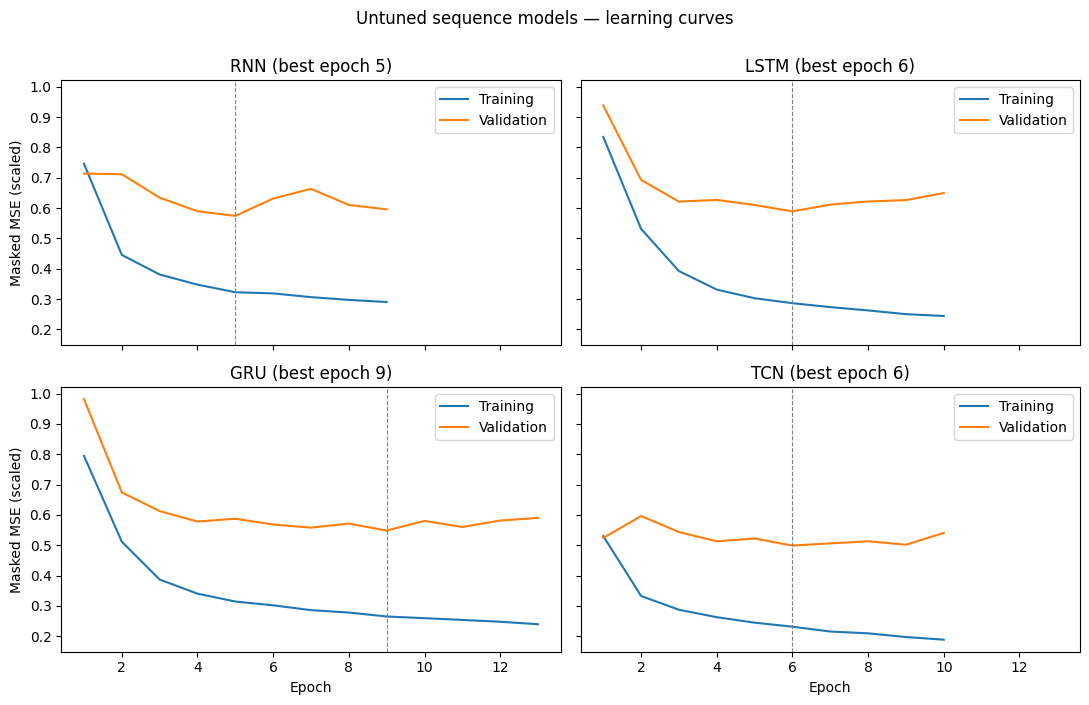

In [27]:
# 21. Learning curves for the untuned sequence models:

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, res in zip(axes.ravel(), untuned_results):
    ep = range(1, len(res["train_curve"]) + 1)
    ax.plot(ep, res["train_curve"], label="Training")
    ax.plot(ep, res["val_curve"], label="Validation")
    ax.axvline(res["Best epoch"], color="gray", ls="--", lw=0.8)
    ax.set_title(f"{res['Model']} (best epoch {res['Best epoch']})")
    ax.legend()
for ax in axes[-1]:
    ax.set_xlabel("Epoch")
for ax in axes[:, 0]:
    ax.set_ylabel("Masked MSE (scaled)")
fig.suptitle("Untuned sequence models — learning curves", y=1.0)
fig.tight_layout()
plt.show()

In [28]:
# 22. Controlled comparison so far (Stage 1 models + new untuned models) and the HPO target:

base = final_validation_comparison[["Model"] + METRIC_COLS].copy()
new_rows = pd.DataFrame([
    {"Model": f"{r['Model']} (untuned)", **{c: r[c] for c in METRIC_COLS}} for r in untuned_results
])
stage2_untuned = pd.concat([base, new_rows], ignore_index=True)
stage2_untuned["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - stage2_untuned["Validation RMSE"]) / baseline_rmse * 100
)
stage2_untuned = stage2_untuned.sort_values("Validation RMSE").reset_index(drop=True)
display(stage2_untuned.round(4))

# Pre-declared rule: tune the new model with the lowest untuned validation RMSE.
tune_name = min(untuned_results, key=lambda r: r["Validation RMSE"])["Model"]
print(f"Model selected for HPO (best untuned new model by validation RMSE): {tune_name}")

,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,TCN (untuned),5.1500,3.5229,117638,163.8545,1.4493,50.3925
1,GRU (untuned),5.3998,3.7145,18566,44.1891,0.2154,47.9863
2,RNN (untuned),5.5259,3.8085,9222,10.6064,0.1435,46.7721
3,LSTM (untuned),5.5968,3.9163,23238,28.8792,0.3256,46.0892
4,MLP (untuned),5.6066,3.7328,73286,4.5206,0.0050,45.9948
5,MLP (grid-search selected),5.6257,3.7672,73286,4.0440,0.0078,45.8105
6,1D CNN,7.3974,5.4990,5958,9.0752,0.0967,28.7448
7,Seasonal naive,10.3816,7.7813,0,0.0000,0.0012,0.0000


Model selected for HPO (best untuned new model by validation RMSE): TCN


In [29]:
# 23. HPO: full pre-declared grid on the selected model (12 trials, same seed/split/windows/metrics):

hpo_rows, hpo_models = [], {}
for trial, (lr, hidden_size, dropout) in enumerate(HPO_TRIALS, start=1):
    res, mdl = train_model(tune_name, lr, hidden_size, dropout)
    hpo_rows.append({
        "Trial": trial, "Learning rate": lr, "Hidden size": hidden_size, "Dropout": dropout,
        "Validation RMSE": res["Validation RMSE"], "Validation MAE": res["Validation MAE"],
        "Trainable parameters": res["Trainable parameters"],
        "Training time (seconds)": res["Training time (seconds)"],
        "Best epoch": res["Best epoch"], "Epochs run": res["Epochs run"],
    })
    hpo_models[trial] = mdl
    print(f"Trial {trial:2d}/{HPO_BUDGET} | lr={lr} hidden={hidden_size} dropout={dropout} "
          f"| val RMSE {res['Validation RMSE']:.4f} | stopped at epoch {res['Epochs run']}")

Trial  1/12 | lr=0.001 hidden=32 dropout=0.1 | val RMSE 5.1929 | stopped at epoch 13
Trial  2/12 | lr=0.001 hidden=32 dropout=0.3 | val RMSE 5.1180 | stopped at epoch 15
Trial  3/12 | lr=0.001 hidden=64 dropout=0.1 | val RMSE 5.1500 | stopped at epoch 10
Trial  4/12 | lr=0.001 hidden=64 dropout=0.3 | val RMSE 5.1077 | stopped at epoch 13
Trial  5/12 | lr=0.005 hidden=32 dropout=0.1 | val RMSE 5.1776 | stopped at epoch 10
Trial  6/12 | lr=0.005 hidden=32 dropout=0.3 | val RMSE 5.2012 | stopped at epoch 10
Trial  7/12 | lr=0.005 hidden=64 dropout=0.1 | val RMSE 5.1752 | stopped at epoch 5
Trial  8/12 | lr=0.005 hidden=64 dropout=0.3 | val RMSE 5.2465 | stopped at epoch 8
Trial  9/12 | lr=0.01 hidden=32 dropout=0.1 | val RMSE 5.2911 | stopped at epoch 9
Trial 10/12 | lr=0.01 hidden=32 dropout=0.3 | val RMSE 5.3403 | stopped at epoch 7
Trial 11/12 | lr=0.01 hidden=64 dropout=0.1 | val RMSE 5.3611 | stopped at epoch 5
Trial 12/12 | lr=0.01 hidden=64 dropout=0.3 | val RMSE 5.4203 | stopped a

,Learning rate,Hidden size,Dropout,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Best epoch,Epochs run
Trial,,,,,,,,,
1,0.001,32,0.1,5.1929,3.6640,30150,88.4700,9,13
2,0.001,32,0.3,5.1180,3.5064,30150,108.2514,13,15
3,0.001,64,0.1,5.1500,3.5229,117638,150.6396,6,10
4,0.001,64,0.3,5.1077,3.5259,117638,208.2391,9,13
5,0.005,32,0.1,5.1776,3.6389,30150,64.6467,6,10
6,0.005,32,0.3,5.2012,3.6370,30150,69.9923,6,10
7,0.005,64,0.1,5.1752,3.6055,117638,76.0019,1,5
8,0.005,64,0.3,5.2465,3.5668,117638,129.2567,4,8
9,0.010,32,0.1,5.2911,3.6893,30150,58.7633,5,9


Best trial: 2 -> lr=0.001, hidden=32, dropout=0.3, val RMSE 5.1180


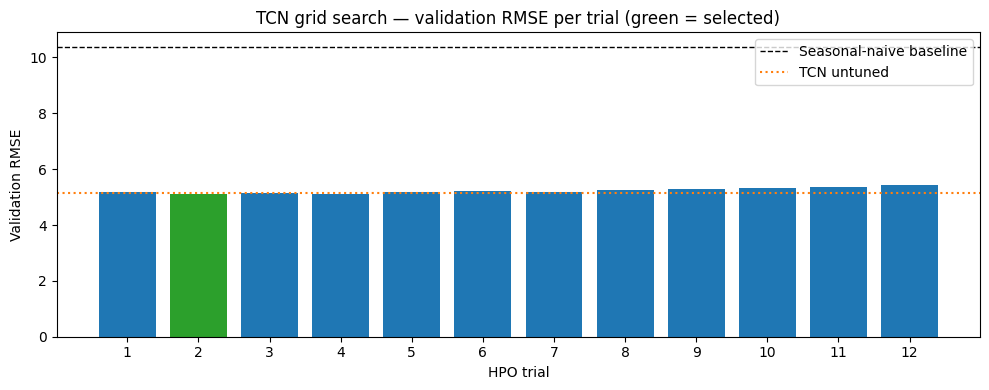

In [30]:
# 24. HPO evidence — trials table and plot:

hpo_df = pd.DataFrame(hpo_rows)
display(hpo_df.round(4).set_index("Trial"))

# Selection: lowest validation RMSE; ties (within 0.5%) go to fewer parameters (rule declared in Cell 17).
best_rmse = hpo_df["Validation RMSE"].min()
near_best = hpo_df[hpo_df["Validation RMSE"] <= best_rmse * 1.005]
best_trial = int(near_best.sort_values(["Trainable parameters", "Validation RMSE"]).iloc[0]["Trial"])
best_row = hpo_df[hpo_df["Trial"] == best_trial].iloc[0]
tuned_model = hpo_models[best_trial]
print(f"Best trial: {best_trial} -> lr={best_row['Learning rate']}, hidden={int(best_row['Hidden size'])}, "
      f"dropout={best_row['Dropout']}, val RMSE {best_row['Validation RMSE']:.4f}")

untuned_ref = next(r for r in untuned_results if r["Model"] == tune_name)["Validation RMSE"]
colors = ["tab:green" if t == best_trial else "tab:blue" for t in hpo_df["Trial"]]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hpo_df["Trial"], hpo_df["Validation RMSE"], color=colors)
ax.axhline(baseline_rmse, color="k", ls="--", lw=1, label="Seasonal-naive baseline")
ax.axhline(untuned_ref, color="tab:orange", ls=":", lw=1.5, label=f"{tune_name} untuned")
ax.set_xticks(hpo_df["Trial"])
ax.set_xlabel("HPO trial")
ax.set_ylabel("Validation RMSE")
ax.set_title(f"{tune_name} grid search — validation RMSE per trial (green = selected)")
ax.legend()
fig.tight_layout()
plt.show()

In [31]:
# 25. Full controlled comparison and final model selection (validation evidence only):

# Registry of every trained model: name -> (architecture spec, model object).
registry = {
    "MLP (untuned)": ({"class": "TimeSeriesMLP", "kwargs": {}}, mlp_model),
    "1D CNN": ({"class": "TimeSeriesCNN", "kwargs": {}}, cnn_model),
    "MLP (grid-search selected)": (
        {"class": "GridSearchMLP",
         "kwargs": {"hidden_sizes": list(best_mlp_config["hidden_sizes"]), "dropout": best_mlp_config["dropout"]}},
        selected_mlp),
}
for name, mdl in untuned_models.items():
    registry[f"{name} (untuned)"] = (arch_spec(name, DEFAULT_CFG["hidden_size"], DEFAULT_CFG["dropout"]), mdl)
tuned_label = f"{tune_name} (HPO-tuned)"
registry[tuned_label] = (arch_spec(tune_name, int(best_row["Hidden size"]), float(best_row["Dropout"])), tuned_model)

# Add the tuned model's row to the comparison table.
tuned_row = pd.DataFrame([{
    "Model": tuned_label,
    "Validation RMSE": best_row["Validation RMSE"], "Validation MAE": best_row["Validation MAE"],
    "Trainable parameters": int(best_row["Trainable parameters"]),
    "Training time (seconds)": best_row["Training time (seconds)"],
    "Validation prediction time (seconds)": evaluate_model(tuned_model)[2],
}])
stage2_final = pd.concat([stage2_untuned[["Model"] + METRIC_COLS], tuned_row], ignore_index=True)
stage2_final["RMSE improvement over baseline (%)"] = (
    (baseline_rmse - stage2_final["Validation RMSE"]) / baseline_rmse * 100
)
stage2_final = stage2_final.sort_values("Validation RMSE").reset_index(drop=True)
display(stage2_final.round(4))

# Selection rule (declared in Cell 17): lowest validation RMSE among trained models;
# within 0.5% of the best -> fewer parameters wins. The baseline is a reference, not a candidate.
candidates = stage2_final[stage2_final["Model"] != "Seasonal naive"]
best_r = candidates["Validation RMSE"].min()
close = candidates[candidates["Validation RMSE"] <= best_r * 1.005]
final_row = close.sort_values(["Trainable parameters", "Validation RMSE"]).iloc[0]
final_name = final_row["Model"]
final_spec, final_model = registry[final_name]

print(f"FINAL MODEL: {final_name}")
print(f"  Validation RMSE {final_row['Validation RMSE']:.4f} | MAE {final_row['Validation MAE']:.4f} "
      f"| params {int(final_row['Trainable parameters']):,} "
      f"| improvement over baseline {final_row['RMSE improvement over baseline (%)']:.2f}%")
print(f"  Architecture spec: {final_spec}")

,Model,Validation RMSE,Validation MAE,Trainable parameters,Training time (seconds),Validation prediction time (seconds),RMSE improvement over baseline (%)
0,TCN (HPO-tuned),5.1180,3.5064,30150,108.2514,0.3922,50.7015
1,TCN (untuned),5.1500,3.5229,117638,163.8545,1.4493,50.3925
2,GRU (untuned),5.3998,3.7145,18566,44.1891,0.2154,47.9863
3,RNN (untuned),5.5259,3.8085,9222,10.6064,0.1435,46.7721
4,LSTM (untuned),5.5968,3.9163,23238,28.8792,0.3256,46.0892
5,MLP (untuned),5.6066,3.7328,73286,4.5206,0.0050,45.9948
6,MLP (grid-search selected),5.6257,3.7672,73286,4.0440,0.0078,45.8105
7,1D CNN,7.3974,5.4990,5958,9.0752,0.0967,28.7448
8,Seasonal naive,10.3816,7.7813,0,0.0000,0.0012,0.0000


FINAL MODEL: TCN (HPO-tuned)
  Validation RMSE 5.1180 | MAE 3.5064 | params 30,150 | improvement over baseline 50.70%
  Architecture spec: {'class': 'TCNForecaster', 'kwargs': {'hidden_size': 32, 'dropout': 0.3}}


In [32]:
# 26. Checkpoint the selected model + configuration + preprocessing state in ONE file for the final stage:

CHECKPOINT_PATH = "stage2_checkpoint.pt"

final_rmse, final_mae, _, final_val_pred = evaluate_model(final_model)

checkpoint = {
    # Model
    "model_name": final_name,
    "arch_spec": final_spec,
    "state_dict": {k: v.detach().cpu() for k, v in final_model.state_dict().items()},
    # Configuration
    "hpo_space": HPO_SPACE,
    "tuned_model_family": tune_name,
    "best_hpo_trial": {"trial": best_trial, "lr": float(best_row["Learning rate"]),
                       "hidden_size": int(best_row["Hidden size"]), "dropout": float(best_row["Dropout"])},
    "training": {"max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE, "patience": PATIENCE,
                 "grad_clip": GRAD_CLIP, "optimizer": "Adam", "loss": "masked_mse", "seed": SEED},
    "validation_metrics": {"rmse": float(final_rmse), "mae": float(final_mae),
                           "baseline_rmse": float(baseline_rmse)},
    # Preprocessing state (needed to transform test data exactly like train data)
    "features": list(features),
    "target_col": TARGET_COL,
    "target_idx": int(target_idx),
    "lookback": int(LOOKBACK),
    "horizon": int(HORIZON),
    "missing_value_code": -200,
    "imputation": "forward-fill, then training-set median fallback",
    "training_feature_medians": {k: float(v) for k, v in training_feature_medians.items()},
    "scaler_mean": [float(x) for x in scaler.mean_],
    "scaler_scale": [float(x) for x in scaler.scale_],
    "target_mean": float(target_mean),
    "target_scale": float(target_scale),
}
torch.save(checkpoint, CHECKPOINT_PATH)
print(f"Saved checkpoint to {CHECKPOINT_PATH}")

# ---- Verify the checkpoint round-trips (rebuild model, reload weights, reproduce predictions) ----
loaded = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
reloaded_model = build_from_spec(loaded["arch_spec"]).to(device)
reloaded_model.load_state_dict(loaded["state_dict"])
reloaded_model.eval()

_, _, _, reloaded_pred = evaluate_model(reloaded_model)
print("Reloaded predictions match saved model:", np.allclose(reloaded_pred, final_val_pred, atol=1e-5))

# Preprocessing state is sufficient to reproduce the scaled validation inputs.
mean = np.array(loaded["scaler_mean"]); scale = np.array(loaded["scaler_scale"])
rescaled_val = (val_processed[loaded["features"]].to_numpy() - mean) / scale
print("Saved scaler state reproduces scaled validation inputs:", np.allclose(rescaled_val, val_scaled))

Saved checkpoint to stage2_checkpoint.pt
Reloaded predictions match saved model: True
Saved scaler state reproduces scaled validation inputs: True


### Predicted vs. actual (final model, validation set)

Plots below compare the final model's forecasts with the observed benzene values (original units). Input windows overlap (stride = 6 h), while the six-hour target blocks do not overlap; the time-series panels show the 1-step-ahead and the last-step-ahead forecast of every window. Hours with a missing target are left blank in the plots and excluded from the metrics.

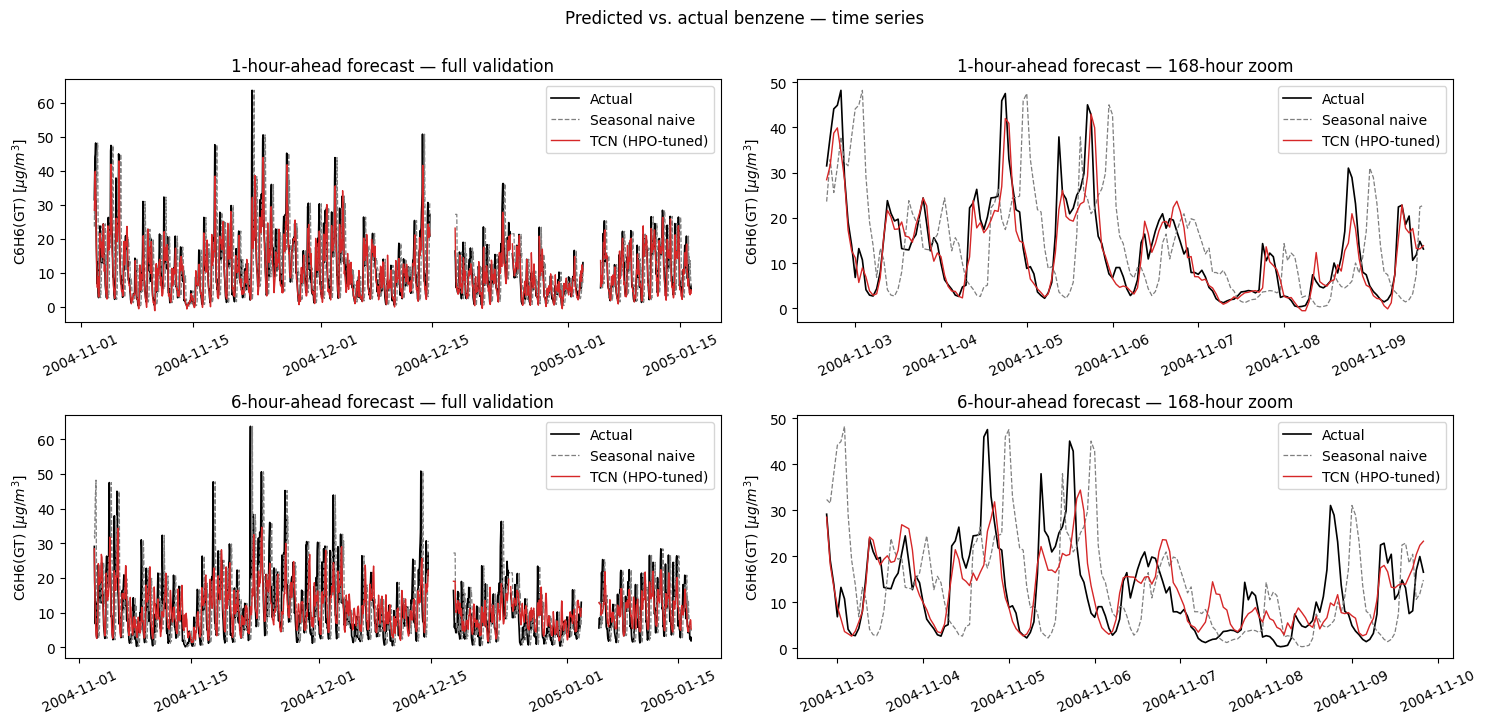

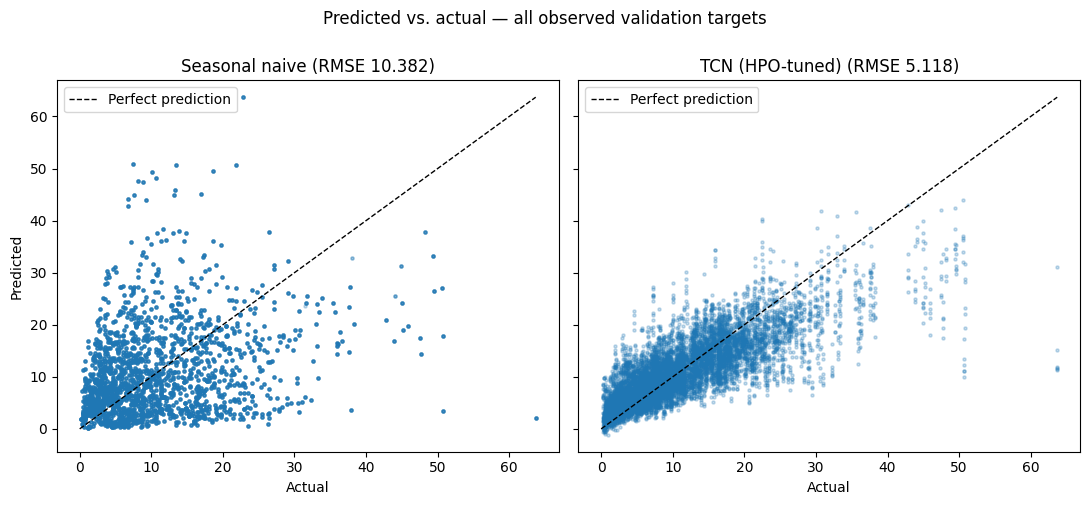

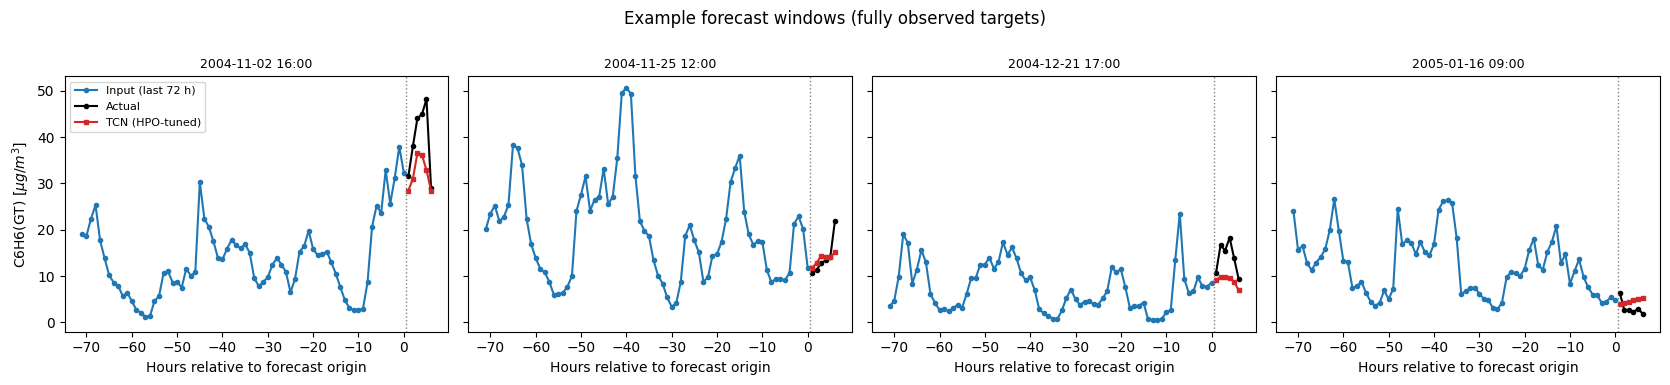

In [33]:
# 27. Predicted vs. actual plots — final model vs. seasonal-naive baseline (validation set, original units):

def plot_predicted_vs_actual(pred_original, label, zoom_hours=168, n_examples=4):
    n_windows = len(pred_original)
    pos = np.arange(n_windows)[:, None] * STRIDE + LOOKBACK + np.arange(HORIZON)[None, :]   # val_df row each prediction targets
    times = val_df.index.to_numpy()[pos]                                             # [n_windows, HORIZON]

    actual = np.where(observed_val, y_val_original, np.nan)
    pred = np.where(observed_val, pred_original, np.nan)
    base = np.where(observed_val, baseline_pred_original, np.nan)
    steps = sorted({0, HORIZON - 1})

    # Zoom on the zoom_hours-long stretch with the most observed targets (1-step-ahead).
    zoom_windows = max(1, (zoom_hours + STRIDE - 1) // STRIDE)
    cover = np.convolve(observed_val[:, 0].astype(float), np.ones(zoom_windows), mode="valid")
    z0 = int(cover.argmax()); z1 = z0 + zoom_windows

    # --- Figure A: time series, full validation (left) and zoom (right), one row per forecast step ---
    fig, axes = plt.subplots(len(steps), 2, figsize=(15, 3.6 * len(steps)), squeeze=False)
    for r, k in enumerate(steps):
        for c, (sl, title) in enumerate([(slice(None), "full validation"), (slice(z0, z1), f"{zoom_hours}-hour zoom")]):
            ax = axes[r, c]
            ax.plot(times[sl, k], actual[sl, k], color="k", lw=1.2, label="Actual")
            ax.plot(times[sl, k], base[sl, k], color="tab:gray", lw=0.9, ls="--", label="Seasonal naive")
            ax.plot(times[sl, k], pred[sl, k], color="tab:red", lw=1.0, label=label)
            ax.set_title(f"{k + 1}-hour-ahead forecast — {title}")
            ax.set_ylabel(rf"{TARGET_COL} [$\mu g/m^3$]")
            ax.tick_params(axis="x", rotation=25)
            ax.legend(loc="upper right")
    fig.suptitle("Predicted vs. actual benzene — time series", y=1.0)
    fig.tight_layout(); plt.show()

    # --- Figure B: scatter of predicted vs. actual over all observed targets ---
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
    lim = [0, float(np.nanmax(actual))]
    for ax, p, name in [(axes[0], base, "Seasonal naive"), (axes[1], pred, label)]:
        ax.scatter(actual[observed_val], p[observed_val], s=5, alpha=0.25)
        ax.plot(lim, lim, "k--", lw=1, label="Perfect prediction")
        rmse = np.sqrt(np.mean((p[observed_val] - actual[observed_val]) ** 2))
        ax.set_title(f"{name} (RMSE {rmse:.3f})")
        ax.set_xlabel("Actual"); ax.legend(loc="upper left")
    axes[0].set_ylabel("Predicted")
    fig.suptitle("Predicted vs. actual — all observed validation targets", y=1.0)
    fig.tight_layout(); plt.show()

    # --- Figure C: example windows (input context + HORIZON-hour forecast vs. actual) ---
    full_obs = np.where(observed_val.all(axis=1))[0]        # windows whose whole target is observed
    if len(full_obs) > 0:
        chosen = full_obs[np.linspace(0, len(full_obs) - 1, min(n_examples, len(full_obs))).astype(int)]
        fig, axes = plt.subplots(1, len(chosen), figsize=(4.2 * len(chosen), 3.8), sharey=True, squeeze=False)
        for ax, i in zip(axes[0], chosen):
            context = X_val[i, :, target_idx] * target_scale + target_mean   # imputed input benzene
            ax.plot(range(-LOOKBACK + 1, 1), context, color="tab:blue", marker="o", ms=3, label="Input (last %d h)" % LOOKBACK)
            ax.plot(range(1, HORIZON + 1), y_val_original[i], color="k", marker="o", ms=3, label="Actual")
            ax.plot(range(1, HORIZON + 1), pred_original[i], color="tab:red", marker="s", ms=3, label=label)
            ax.axvline(0.5, color="gray", ls=":", lw=1)
            ax.set_title(str(val_df.index[i * STRIDE + LOOKBACK])[:16], fontsize=9)
            ax.set_xlabel("Hours relative to forecast origin")
        axes[0, 0].set_ylabel(rf"{TARGET_COL} [$\mu g/m^3$]"); axes[0, 0].legend(fontsize=8)
        fig.suptitle("Example forecast windows (fully observed targets)", y=1.0)
        fig.tight_layout(); plt.show()

_, _, _, final_val_pred_plot = evaluate_model(final_model)
plot_predicted_vs_actual(final_val_pred_plot, final_name)
